# Session 6 lab: From default charts to decision charts

<p class="lead">
Take charts that technically work but mislead or tire the reader, and rebuild them so the important comparison is obvious, honest and labelled.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/06_visualisation_principles_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The head of the retail business says:

> *"I get charts every week and I can never tell what I am supposed to see. Next month I want one page that shows me where we lose money and whether discounting is the reason."*

Today you build the habits that make that page possible: every chart has a task, one highlight, honest axes and a title that states the finding.

> **About the data**
>
> We use the **Superstore** sample published by Tableau. It describes a **fictitious** company. Sales and Profit are in **source monetary units**; the currency is not stated.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G5 |
| **Independent tasks** | Same skills, new charts, on your own or in pairs | I1–I5 |
| **Challenge** | A decision chart and a debugging task | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Write and reuse a small **style helper** for message titles and quiet axes.
2. Redesign a crowded **pie**, a **truncated bar axis** and a **rainbow line spaghetti**.
3. Draw a **histogram**, a **scatter plot** and **small multiples** and say what each shows.
4. Choose **sequential** or **diverging** colour for a heatmap.
5. Write a short **critique** for every before/after pair.

**Evidence you keep:** three before/after chart pairs with critiques, your one-, two- and many-variable views, and a critique log.

Before you start, work through the [Session 6 lecture](06_visualisation_principles_lecture.md).

---

# Guided practice

### G1 (Core): Load the data and build a style helper

Run the setup cell first.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


Every chart in this lab uses the same two small functions:

- `finish(ax, title, subtitle, xlabel, ylabel)` writes a bold **message title**, a smaller **subtitle** for scope and units, and the axis labels.
- `highlight(labels, focus)` returns one colour per label: orange for the label(s) in `focus`, grey for the rest.

Writing them once means every chart gets the same look, and you can copy them into later sessions.

In [2]:
import numpy as np
from matplotlib.colors import TwoSlopeNorm

df = load_orders()

GREY, HIGHLIGHT, INK, BLUE = "#c9c7c1", "#eb6834", "#55534e", "#2a78d6"
rng = np.random.default_rng(6)  # fixed seed for the small random jitter used in G4


def finish(ax, title, subtitle="", xlabel="", ylabel=""):
    """Course chart style: message title, scope subtitle, axis labels, quiet frame."""
    extra_lines = subtitle.count("\n")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold",
                 pad=(24 + 12 * extra_lines) if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=INK, va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    return ax


def highlight(labels, focus):
    """One colour per label: HIGHLIGHT for the label(s) in focus, GREY for the rest."""
    focus = [focus] if isinstance(focus, str) else list(focus)
    return [HIGHLIGHT if label in focus else GREY for label in labels]


print("Order lines:", len(df), "| distinct orders:", df["order_id"].nunique())

Order lines: 6815 | distinct orders: 3388


---

### G2 (Core): Bad chart 1, the crowded pie

A colleague wants to show "which sub-categories are in the most orders". Their chart:

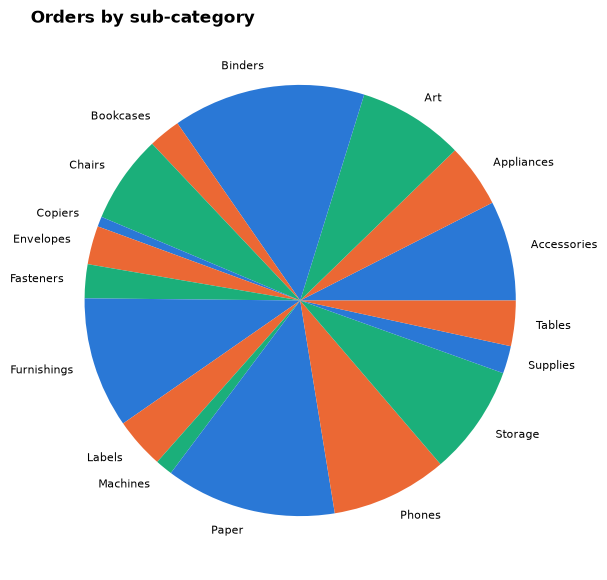

Slices add up to: 6232 | distinct orders: 3388


In [3]:
orders_by_sub = df.groupby("sub_category")["order_id"].nunique()

orders_by_sub.plot(kind="pie", figsize=(7, 7), title="Orders by sub-category", textprops={"fontsize": 8})
plt.ylabel("")
plt.show()

print("Slices add up to:", orders_by_sub.sum(), "| distinct orders:", df["order_id"].nunique())

Read the printed line. The slices add up to **more** than the number of orders, because one order can contain several sub-categories (you met this overlap in Session 2). A pie says "these parts make one whole", so here it is not just hard to read; it is **wrong**.

Problems:

1. Seventeen slices: angles of similar size cannot be compared.
2. Alphabetical order around the circle: the ranking is hidden.
3. The parts overlap, so a part-of-a-whole chart misstates the data.

The redesign: the **share of orders that contain** each sub-category, as sorted bars, with the largest highlighted. The subtitle warns that shares add up to more than 100%.

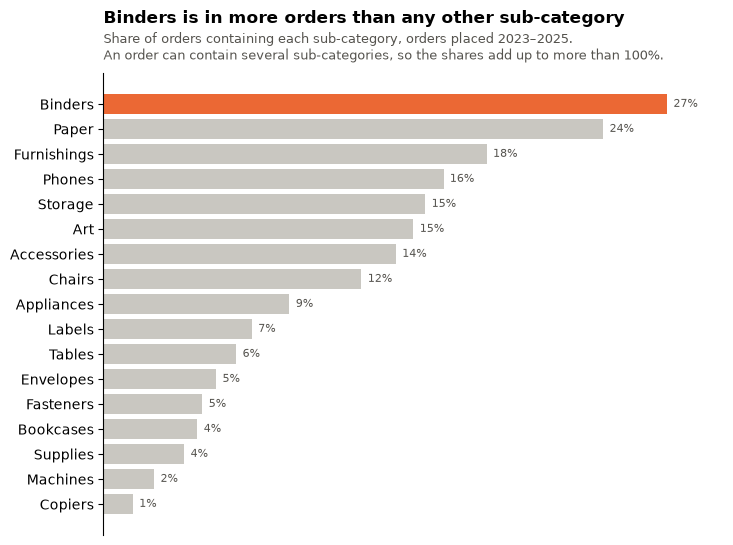

In [4]:
share = (orders_by_sub / df["order_id"].nunique() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(share.index, share, color=highlight(share.index, share.idxmax()))
for name, value in share.items():
    ax.text(value + 0.3, name, f"{value:.0f}%", va="center", fontsize=8, color=INK)
ax.set_xlim(0, share.max() * 1.1)
ax.grid(False)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
finish(ax, f"{share.idxmax()} is in more orders than any other sub-category",
       "Share of orders containing each sub-category, orders placed 2023–2025.\n"
       "An order can contain several sub-categories, so the shares add up to more than 100%.")
plt.show()

> **Write your critique**
>
> In your evidence log, write two or three sentences: what was wrong with the pie, which principle each change applies (task, encoding, highlight, honest framing), and what a reader can now see in seconds.

---

### G3 (Core): One variable, a histogram

How big is a typical order? First add up Sales per order (an order has several lines), then look at the **distribution**.

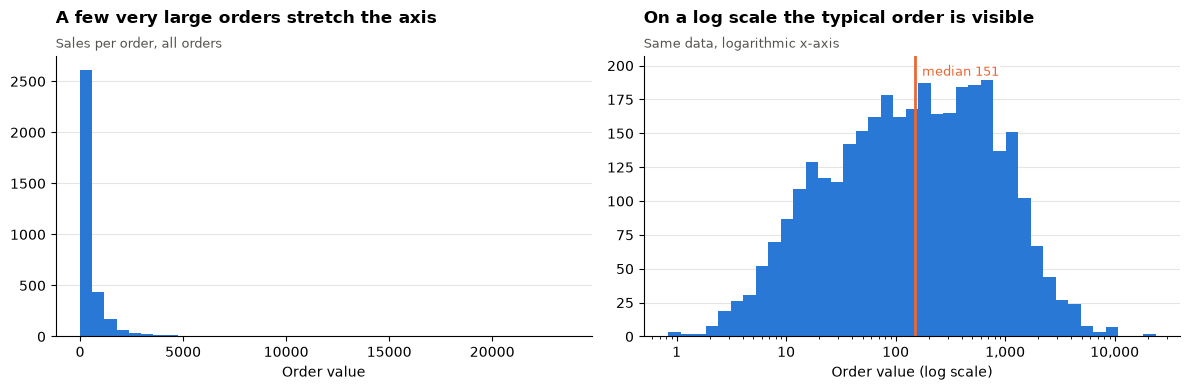

Median order value: 151.46 | mean: 466.64


In [5]:
order_value = df.groupby("order_id")["sales"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(order_value, bins=40, color=BLUE)
ax1.grid(axis="x", visible=False)
finish(ax1, "A few very large orders stretch the axis", "Sales per order, all orders", xlabel="Order value")

bins = np.geomspace(order_value.min(), order_value.max(), 40)
ax2.hist(order_value, bins=bins, color=BLUE)
ax2.set_xscale("log")
ax2.axvline(order_value.median(), color=HIGHLIGHT, linewidth=2)
ax2.text(order_value.median() * 1.15, ax2.get_ylim()[1] * 0.97, f"median {order_value.median():,.0f}",
         color=HIGHLIGHT, fontsize=9, va="top", bbox={"facecolor": "white", "linewidth": 0, "pad": 1})
ax2.xaxis.set_major_formatter("{x:,.0f}")
ax2.grid(axis="x", visible=False)
finish(ax2, "On a log scale the typical order is visible", "Same data, logarithmic x-axis",
       xlabel="Order value (log scale)")
fig.tight_layout()
plt.show()

print(f"Median order value: {order_value.median():,.2f} | mean: {order_value.mean():,.2f}")

The left histogram is squeezed against the axis by a long right tail. On a **log scale** each step to the right multiplies the value, so the bulk of orders spreads out. The mean is pulled above the median by the large orders: Session 4 goes deeper into this.

> **Your turn:** change the code in the next cell and run it again.

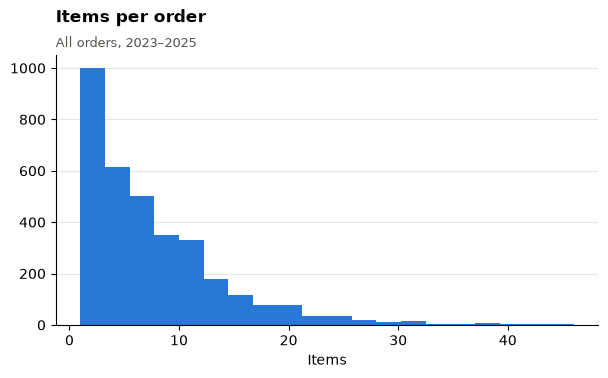

In [6]:
# 1. Replace the values line with:
#    values = df.groupby("order_id")["order_to_ship_days"].first()
#    (days from order to shipping; every line of an order has the same value, so take the first).
# 2. Change the number of bins (try 8 and 30). Which value of bins shows the shape best?
# 3. Rewrite the title so it states what you see.
values = df.groupby("order_id")["quantity"].sum()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(values, bins=20, color=BLUE)
ax.grid(axis="x", visible=False)
finish(ax, "Items per order", "All orders, 2023–2025", xlabel="Items")
plt.show()

---

### G4 (Core): Two variables, discount and profit

Does discounting hurt profit? A first scatter plot of every order line:

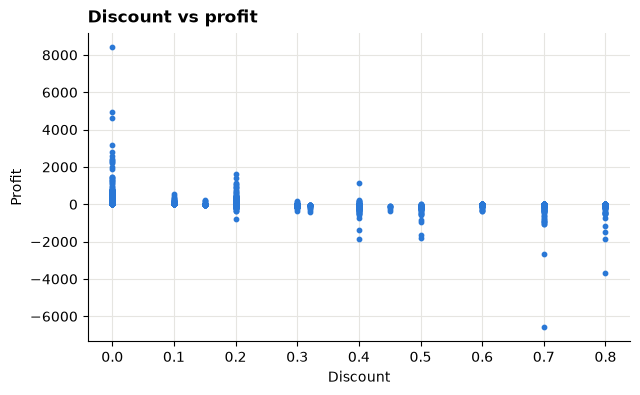

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["discount"], df["profit"], s=10)
finish(ax, "Discount vs profit", xlabel="Discount", ylabel="Profit")
plt.show()

Thousands of points sit on top of each other in a few vertical stripes (the discount levels), and a handful of huge values set the scale. Three fixes:

1. Use **profit ratio** (Profit ÷ Sales) so a large and a small line are comparable.
2. Add a little random **jitter** sideways and make points **transparent**, so overlapping points become visible as darker areas.
3. Add the **total** profit ratio at each discount level (a ratio of sums, as in Session 5) and a zero line.

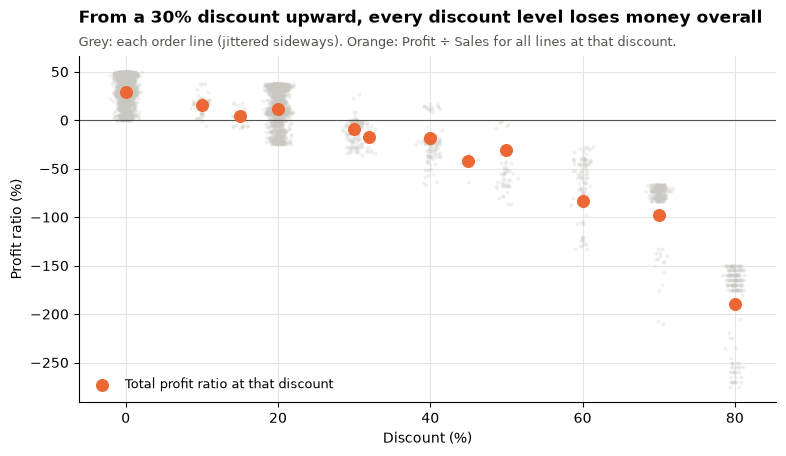

,sales,profit,lines,profit_ratio_pct
discount,,,,
0.00,"748,350.60","220,093.60",3296,29.40
0.10,"35,773.80","5,796.90",67,16.20
0.15,"18,795.70",881.50,36,4.70
0.20,"521,404.90","57,800.10",2464,11.10
0.30,"72,640.60","-6,593.20",161,-9.10
0.32,"10,776.30","-1,898.90",16,-17.60
0.40,"82,397.70","-15,253.20",138,-18.50
0.45,"2,975.40","-1,264.70",7,-42.50
0.50,"45,117.10","-13,642.00",47,-30.20


In [8]:
line_ratio = df["profit"] / df["sales"] * 100
jitter = rng.normal(0, 0.6, len(df))

by_discount = df.groupby("discount").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                         lines=("row_id", "count"))
by_discount["profit_ratio_pct"] = by_discount["profit"] / by_discount["sales"] * 100

losing = by_discount.index[by_discount["profit_ratio_pct"] < 0]
first_loss = losing.min()
all_after_lose = (by_discount.loc[by_discount.index >= first_loss, "profit_ratio_pct"] < 0).all()
if all_after_lose:
    title = f"From a {first_loss:.0%} discount upward, every discount level loses money overall"
else:
    title = f"Some discount levels from {first_loss:.0%} upward lose money overall"

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(df["discount"] * 100 + jitter, line_ratio, s=8, color=GREY, alpha=0.25, linewidth=0)
ax.scatter(by_discount.index * 100, by_discount["profit_ratio_pct"], s=70, color=HIGHLIGHT, zorder=3,
           label="Total profit ratio at that discount")
ax.axhline(0, color=INK, linewidth=0.8)
ax.legend(frameon=False, loc="lower left", fontsize=9)
finish(ax, title, "Grey: each order line (jittered sideways). Orange: Profit ÷ Sales for all lines at that discount.",
       xlabel="Discount (%)", ylabel="Profit ratio (%)")
plt.show()

by_discount.round(1)

> **Correlation is not causation**
>
> The chart shows that heavily discounted lines lose money. It does **not** prove the discount caused the loss: some products may be both hard to sell (so discounted) and low-margin. Session 8 returns to this. Your title should describe what the chart shows, not claim a cause.

---

### G5 (Core): Many variables, small multiples by region

Is the discount pattern the same everywhere? Draw the orange dots from G4 once per **region**, with the same axes in every panel. Dot size shows how much Sales sits at that discount level.

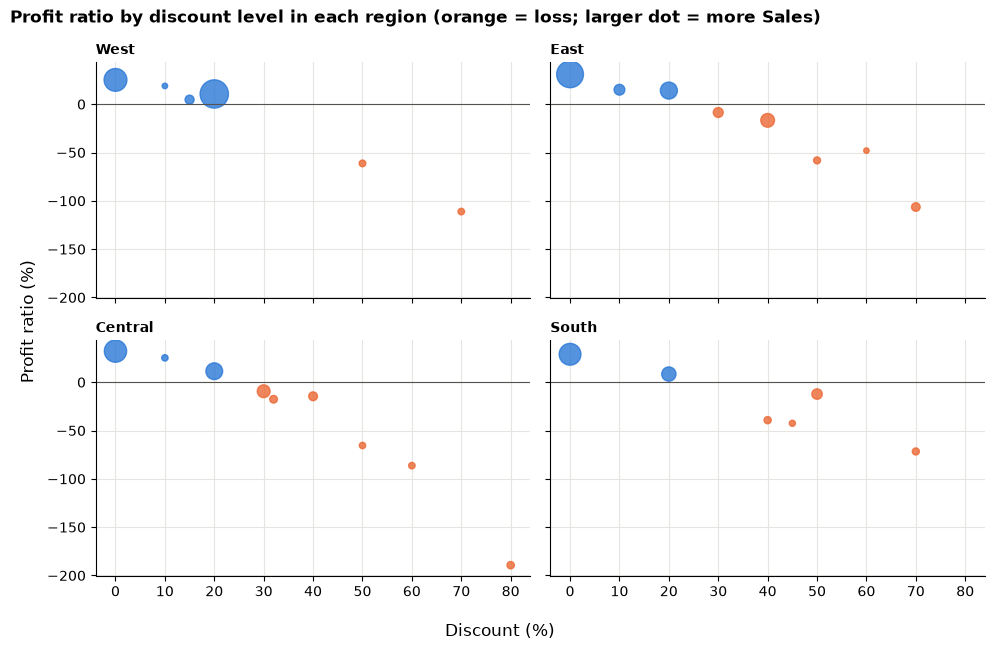

In [9]:
by_region = df.groupby(["region", "discount"]).agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
by_region["profit_ratio_pct"] = by_region["profit"] / by_region["sales"] * 100
region_order = df.groupby("region")["sales"].sum().sort_values(ascending=False).index
biggest = by_region["sales"].max()

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
for ax, region in zip(axes.flat, region_order):
    part = by_region[by_region["region"] == region]
    ax.axhline(0, color=INK, linewidth=0.8)
    ax.scatter(part["discount"] * 100, part["profit_ratio_pct"], s=part["sales"] / biggest * 400 + 15,
               color=[HIGHLIGHT if r < 0 else BLUE for r in part["profit_ratio_pct"]], alpha=0.8)
    ax.set_title(region, loc="left", fontsize=10)
fig.supxlabel("Discount (%)")
fig.supylabel("Profit ratio (%)")
fig.suptitle("Profit ratio by discount level in each region (orange = loss; larger dot = more Sales)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Three variables (discount, profit ratio, region) plus a fourth (Sales, as dot size), and each panel is still easy to read because the axes are shared.

> **What do you notice?**
>
> Write two observations in your log. Which regions use the highest discounts? Is a loss at a given discount level the same in every region?

---

# Independent tasks

### I1 (Core): Bad chart 2, the truncated bar axis

A colleague's chart of profit ratio by segment:

> **Your turn:** change the code in the next cell and run it again.

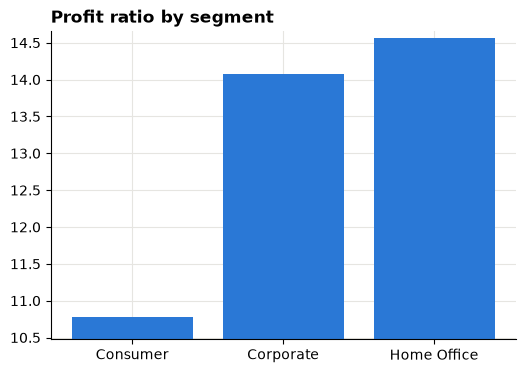

Largest ratio divided by smallest: 1.35


In [10]:
# The colleague's chart. Fix it:
# 1. Delete the ax.set_ylim(...) line so the bars start at zero.
# 2. Write each value on its bar (see the AOV chart in the lecture, Part 7).
# 3. Replace the title with a message title, and use finish() with a subtitle for scope.
segment = df.groupby("segment")[["profit", "sales"]].sum()
segment["profit_ratio_pct"] = segment["profit"] / segment["sales"] * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(segment.index, segment["profit_ratio_pct"], color=BLUE)
ax.set_ylim(segment["profit_ratio_pct"].min() - 0.3, segment["profit_ratio_pct"].max() + 0.1)
ax.set_title("Profit ratio by segment")
plt.show()

print("Largest ratio divided by smallest:", round(segment["profit_ratio_pct"].max() / segment["profit_ratio_pct"].min(), 2))

> **Write your critique**
>
> How many times taller did the tallest bar look than the shortest, before your fix? What is the true ratio (printed above)? Would you still call the gap between segments important?

---

### I2 (Core): Bad chart 3, the rainbow spaghetti

Monthly Sales for every region and category: twelve lines in rainbow colours.

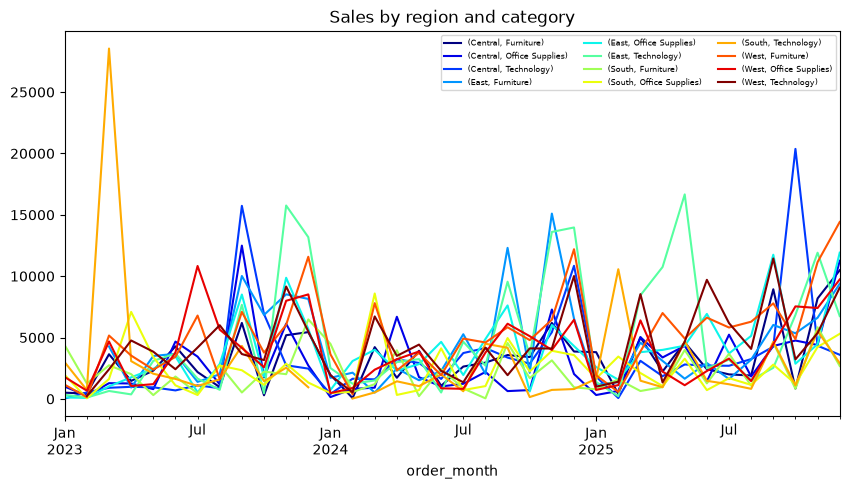

In [11]:
lines = df.groupby(["order_month", "region", "category"])["sales"].sum().unstack(["region", "category"])

with plt.style.context("default"):
    ax = lines.plot(figsize=(10, 5), cmap="jet", title="Sales by region and category")
    ax.legend(fontsize=6, ncol=3)
    plt.show()

Problems: twelve colours with no meaning, a legend you must match line by line, and monthly noise that hides any trend.

The redesign below keeps all twelve series but makes the chart **about one of them**: quarterly instead of monthly to reduce noise, the focus series highlighted with a direct label, the other eleven in grey.

> **Your turn:** change the code in the next cell and run it again.

/var/folders/qr/z61dfxk90914kcsdy7jskgqr0000gn/T/ipykernel_52681/665101469.py:16: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.set_xlim(right=quarterly.index[-1] + pd.Timedelta(days=200))


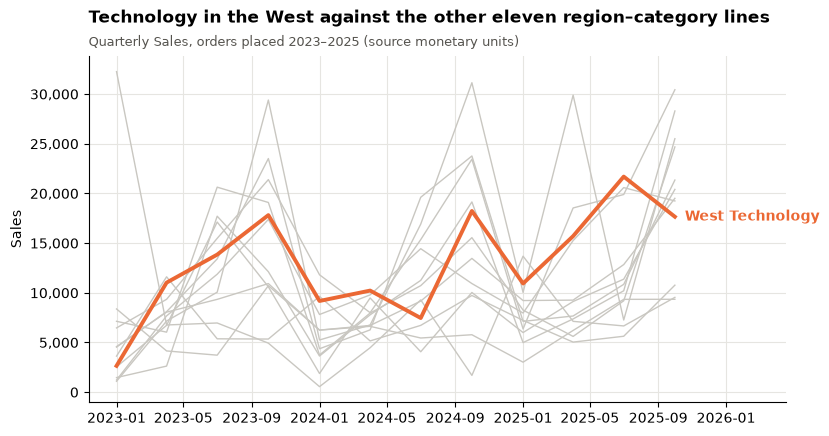

In [12]:
# 1. Change focus to another (region, category) pair, for example ("Central", "Furniture").
# 2. Rewrite the title so it states what the highlighted line shows compared with the others.
# 3. Stretch: replace the whole chart with small multiples, one panel per category,
#    with regions as lines (see lecture Part 9).
quarter = df["order_date"].dt.to_period("Q").dt.to_timestamp()
quarterly = df.groupby([quarter, "region", "category"])["sales"].sum().unstack(["region", "category"])
focus = ("West", "Technology")

fig, ax = plt.subplots(figsize=(9, 4.5))
for key in quarterly.columns:
    if key != focus:
        ax.plot(quarterly.index, quarterly[key], color=GREY, linewidth=1)
ax.plot(quarterly.index, quarterly[focus], color=HIGHLIGHT, linewidth=2.8)
ax.text(quarterly.index[-1], quarterly[focus].iloc[-1], "  " + " ".join(focus), color=HIGHLIGHT,
        va="center", fontweight="bold")
ax.set_xlim(right=quarterly.index[-1] + pd.Timedelta(days=200))
ax.yaxis.set_major_formatter("{x:,.0f}")
finish(ax, f"{focus[1]} in the {focus[0]} against the other eleven region–category lines",
       "Quarterly Sales, orders placed 2023–2025 (source monetary units)", ylabel="Sales")
plt.show()

---

### I3 (Core): Keep a critique log

Like the preparation log in Session 2, a **critique log** records each redesign so someone else can follow your reasoning. Complete it for G2, I1 and I2.

> **Your turn:** change the code in the next cell and run it again.

In [13]:
# Replace each "..." with your own words. One row per before/after pair.
critique_log = pd.DataFrame([
    {"chart": "G2 orders by sub-category", "problem": "...", "change": "...", "principle": "..."},
    {"chart": "I1 profit ratio by segment", "problem": "...", "change": "...", "principle": "..."},
    {"chart": "I2 sales by region and category", "problem": "...", "change": "...", "principle": "..."},
])
critique_log

,chart,problem,change,principle
0,G2 orders by sub-category,...,...,...
1,I1 profit ratio by segment,...,...,...
2,I2 sales by region and category,...,...,...


---

### I4 (Stretch): Sequential or diverging?

Profit ratio for each category and region, as a heatmap. The default uses a **sequential** palette.

> **Your turn:** change the code in the next cell and run it again.

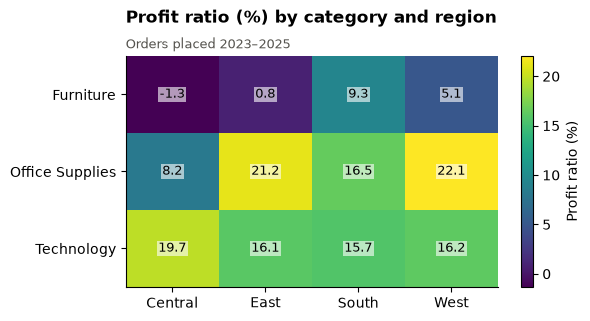

In [14]:
# 1. Run it. Can you see at a glance which cells are losses?
# 2. Change cmap to "RdBu" and centre_on_zero to True. Run again.
# 3. Write one sentence on why the second version fits this measure better.
cmap = "viridis"
centre_on_zero = False

totals = df.groupby(["category", "region"])[["profit", "sales"]].sum()
table = (totals["profit"] / totals["sales"] * 100).unstack()

limit = table.abs().max().max()
norm = TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit) if centre_on_zero else None

fig, ax = plt.subplots(figsize=(6, 3))
image = ax.imshow(table.values, cmap=cmap, norm=norm, aspect="auto")
ax.set_xticks(range(table.shape[1]), table.columns)
ax.set_yticks(range(table.shape[0]), table.index)
ax.grid(False)
for (i, j), value in np.ndenumerate(table.values):
    ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=9, color="black",
            bbox={"facecolor": "white", "alpha": 0.6, "linewidth": 0, "pad": 1})
finish(ax, "Profit ratio (%) by category and region", "Orders placed 2023–2025")
fig.colorbar(image, ax=ax, label="Profit ratio (%)")
plt.show()

---

### I5 (Stretch): Grouping decides the comparison

Proximity (lecture Part 5) decides what readers compare. The chart groups Profit by **category**, with one bar per segment.

> **Your turn:** change the code in the next cell and run it again.

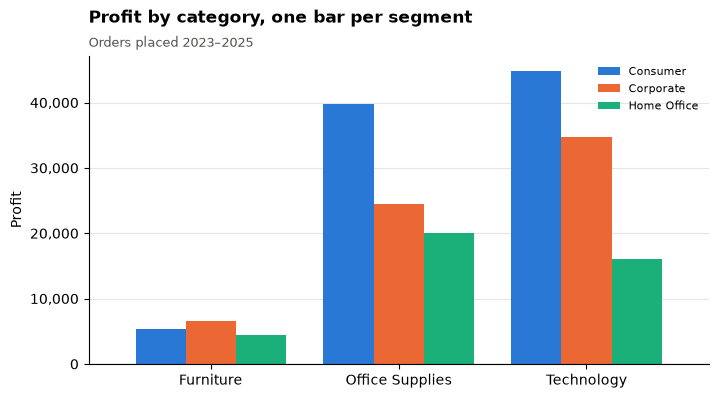

In [15]:
# 1. Change group_by to "segment" and bars_for to "category". Run again.
# 2. Which question does each version answer more easily? Write both questions down.
group_by = "category"
bars_for = "segment"

table = df.groupby([group_by, bars_for])["profit"].sum().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
table.plot(kind="bar", ax=ax, rot=0, width=0.8, color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.axhline(0, color=INK, linewidth=0.8)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8)
ax.yaxis.set_major_formatter("{x:,.0f}")
finish(ax, f"Profit by {group_by}, one bar per {bars_for}", "Orders placed 2023–2025", ylabel="Profit")
plt.show()

---

# Challenge

### C1 (Challenge): One decision chart

The head asked: *"Where do we lose money, and is discounting the reason?"* Build **one** chart that answers the first half and gives evidence on the second.

The starting code below works but is not finished. It plots Profit by sub-category, coloured by **average discount** of the sub-category's lines (orange above the threshold, grey below).

> **Your turn:** change the code in the next cell and run it again.

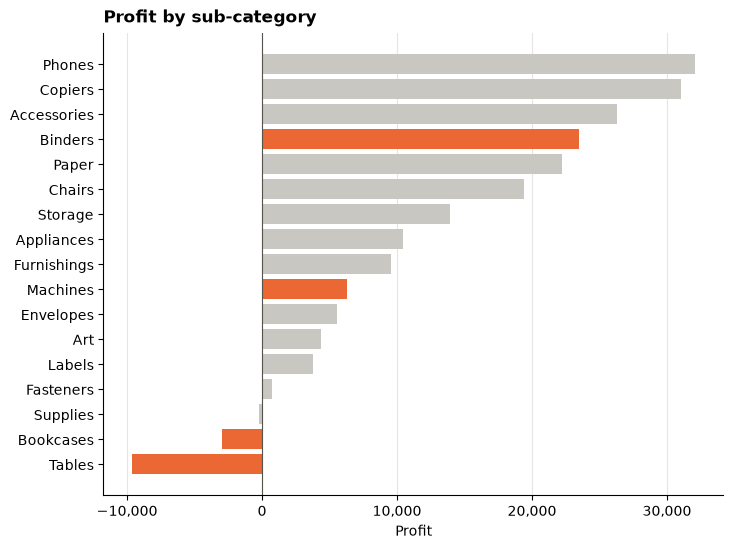

,profit,avg_discount_pct
sub_category,,
Tables,"-9,660.90",25.70
Bookcases,"-2,973.90",21.20
Supplies,-227.10,7.90
Fasteners,729.80,8.40
Labels,"3,770.30",7.50
Art,"4,382.40",7.30
Envelopes,"5,546.30",7.70
Machines,"6,292.60",30.70
Furnishings,"9,580.10",14.20


In [16]:
# 1. Choose a threshold and justify it in your log.
# 2. Replace the title with a message title that is TRUE for the chart, and add a subtitle with scope.
# 3. Add one or two annotations with ax.annotate(...) pointing at the bars that matter.
# 4. Write a five-sentence critique of your own chart: what it shows, what it cannot show.
threshold = 0.20

summary = df.groupby("sub_category").agg(profit=("profit", "sum"), avg_discount=("discount", "mean"))
summary = summary.sort_values("profit")
colours = [HIGHLIGHT if d > threshold else GREY for d in summary["avg_discount"]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(summary.index, summary["profit"], color=colours)
ax.axvline(0, color=INK, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter("{x:,.0f}")
finish(ax, "Profit by sub-category", xlabel="Profit")
plt.show()

summary.assign(avg_discount_pct=summary["avg_discount"] * 100).drop(columns="avg_discount").round(1)

> **Careful with the claim**
>
> Average discount is a **mean of line discounts**, not weighted by Sales. Say so in the subtitle, or compute a Sales-weighted discount instead. And remember G4: a pattern is evidence, not proof of cause.

---

### C2 (Challenge): Debug a dual-axis chart

A colleague sends this chart with the message *"Profit tracks Sales closely, month by month."*

> **Your turn:** change the code in the next cell and run it again.

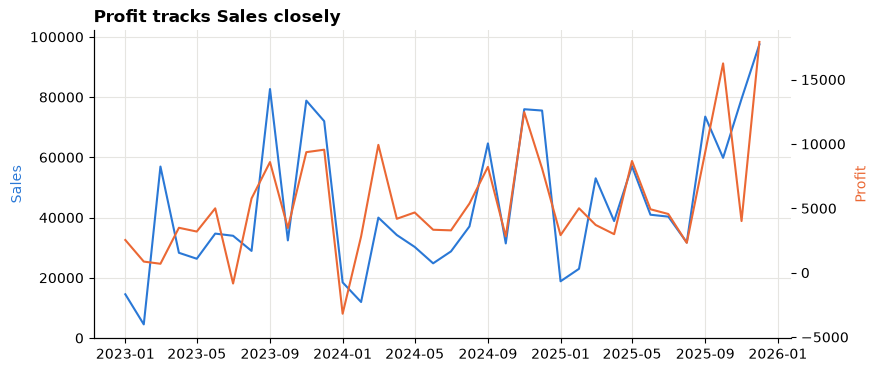

Months with negative Profit: 2


In [17]:
# The colleague's chart. It runs, but the scales were chosen to make the lines look alike.
# 1. Explain in your log why the matching shapes do not prove the message.
# 2. Rebuild it as TWO panels sharing the x-axis: plt.subplots(2, 1, sharex=True),
#    Sales on top, Profit below, each with its own honest axis and a zero line for Profit.
# 3. Stretch: add a third view, the monthly profit ratio, and write a message title for it.
monthly = df.groupby("order_month")[["sales", "profit"]].sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly["sales"], color=BLUE)
ax.set_ylabel("Sales", color=BLUE)
right = ax.twinx()
right.plot(monthly.index, monthly["profit"], color=HIGHLIGHT)
right.set_ylim(monthly["profit"].min() * 1.6, monthly["profit"].max() * 1.05)
right.set_ylabel("Profit", color=HIGHLIGHT)
right.grid(False)
ax.set_title("Profit tracks Sales closely")
plt.show()

print("Months with negative Profit:", (monthly["profit"] < 0).sum())

---

## Exit ticket

1. Which of the three bad charts misled the most, and why?
2. Name the encoding you trust most and the one you trust least.
3. One rule you will now apply to every chart you make.
4. A message title from today that you are proud of.
5. One thing you are still unsure about.

## Evidence to keep

- [ ] Style helper `finish()` and `highlight()` copied into your own notes (G1)
- [ ] Before/after pair 1: crowded pie → sorted share bars, with critique (G2)
- [ ] One-, two- and many-variable views: histogram, scatter, small multiples (G3–G5)
- [ ] Before/after pair 2: truncated axis → honest bars, with critique (I1)
- [ ] Before/after pair 3: rainbow spaghetti → highlighted line, with critique (I2)
- [ ] Critique log (I3)

## After the lab

- Next: the [Session 7 lab](07_trends_and_growth_lab.md), on trends, growth and a decision dashboard.
- Re-read [Storytelling with data](../foundations/storytelling.md): Session 14 builds on today's titles and annotations.